In [3]:
import os
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit





In [2]:
from google.colab import drive
drive.mount('/content/drive')

#connected my drive to colab

Mounted at /content/drive


## Created chunks ( 1d array of audio clips then sliced them in a list of 1d arrays into 5 sec standard)

In [4]:

ds_folder = "/content/drive/MyDrive/datasets/shipsEar_AUDIOS" #folder

chunks_set = []
chunk_min_size = 15000 * 5         #(5sec audio clips) # and 15000 recording
chunk_tags = []                    # the filenames of scattered chunks


for file in sorted(os.listdir(ds_folder)):           # sorted the files so that first 70 % of files are train_b

  if file.endswith(".wav"):

    file_path = os.path.join(ds_folder , file)

    audios , sample_rate = librosa.load(file_path, sr = 15000)  # sr = amplitude record for every single second of audio and 15,000 frames/sec
    # audios = np.array

    for i in range (0 , len(audios) - chunk_min_size + 1 , chunk_min_size):
      chunks_set.append(audios[i: i + chunk_min_size])        # skip the smaller chunks

      chunk_tags.append(file)



## Creating DS_A

In [7]:
temporary , test_a = train_test_split(

                             chunks_set,
                             test_size = 0.15,
                             shuffle = True,
                             random_state = 42,   #preserves the random sequence of chunks_set everytime I reopen colab
)


train_a , val_a = train_test_split(
                                   temporary,
                                   test_size = 0.15 / 0.85,
                                   shuffle = True,
                                   random_state = 42
)


now make dataset b and feature ectr etc etc

In [6]:



train_b , temporary = train_test_split(

                                       chunks_set,
                                       test_size = 0.3,
                                       shuffle=False
)

val_b , test_b = train_test_split(

                                  temporary,
                                  test_size = 0.5,
                                  shuffle=False
)

# Visualizing the Dataset A

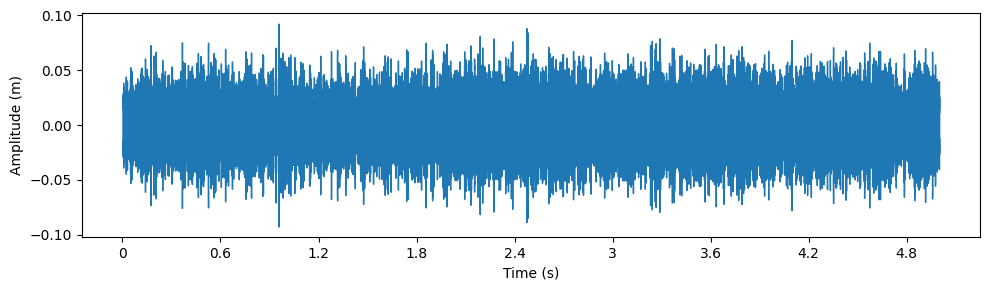

In [25]:
plt.figure(figsize=(10, 3))
librosa.display.waveshow(val_a[0], sr=15000)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (m)')
plt.tight_layout()
plt.show()

# Visualizind DataSet B

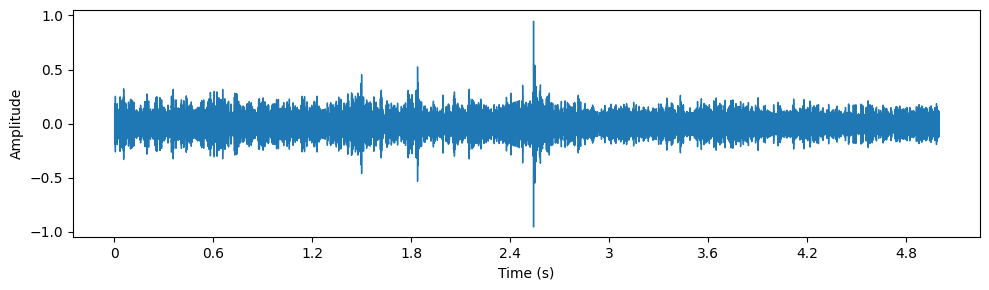

In [24]:
plt.figure(figsize=(10, 3))
librosa.display.waveshow(val_b[0], sr=15000)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.tight_layout()
plt.show()

# Feature Extractions and some feature engineering

1.SRTF

In [30]:
def stft(audio_chunk, sr=15000, n_fft=512, hop_length=256, n_mels=40, n_mfcc=40):

    # 1. STFT (Linear spectrogram magnitude)

    stft_spec = np.abs(librosa.stft(audio_chunk, n_fft=n_fft, hop_length=hop_length))
    stft_db = librosa.amplitude_to_db(stft_spec, ref=np.max)

    return stft_db



def fcfs(audio_chunk, sr=15000, n_fft=512, hop_length=256, n_mels=40, n_mfcc=40):

    # 2. FBank (Mel filter bank spectrogram)

    mel_spec = librosa.feature.melspectrogram(y=audio_chunk, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
    fbank_db = librosa.power_to_db(mel_spec, ref=np.max)

    return fbank_db


def extract_features(audio_chunk, sr=15000, n_fft=512, hop_length=256, n_mels=40, n_mfcc=40):

    # 3. MFCC (Mel-frequency cepstral coefficients)

    mel_spec = librosa.feature.melspectrogram(y=audio_chunk, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
    fbank_db = librosa.power_to_db(mel_spec, ref=np.max)

    mfcc = librosa.feature.mfcc(S=fbank_db, n_mfcc=n_mfcc)

    return mfcc



In [32]:

def extract_features(audio_chunk, sr=15000, n_fft=512, hop_length=256, n_mels=40, n_mfcc=40):
    """
    Extracts STFT, FBank, and MFCC feature matrices from a 1D audio chunk.
    """
    # 1. STFT (Linear spectrogram magnitude)
    stft_spec = np.abs(librosa.stft(audio_chunk, n_fft=n_fft, hop_length=hop_length))
    stft_db = librosa.amplitude_to_db(stft_spec, ref=np.max)

    # 2. FBank (Mel filter bank spectrogram)
    mel_spec = librosa.feature.melspectrogram(y=audio_chunk, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
    fbank_db = librosa.power_to_db(mel_spec, ref=np.max)

    # 3. MFCC (Mel-frequency cepstral coefficients)
    mfcc = librosa.feature.mfcc(S=fbank_db, n_mfcc=n_mfcc)

    return {
        'stft': stft_db,
        'fbank': fbank_db,
        'mfcc': mfcc
    }


#Understand what exactly does it does here in the name of feature engineering



STFT shape: [[-27.928589 -37.087643 -27.018883 ... -27.744808 -54.911266 -40.089832]
 [-23.560532 -19.20742  -18.75935  ... -19.081354 -29.071308 -26.122849]
 [-18.589087 -21.995779 -13.591209 ... -10.425867 -15.913551 -18.563116]
 ...
 [-58.57528  -80.       -80.       ... -80.       -80.       -80.      ]
 [-58.55553  -80.       -80.       ... -80.       -80.       -80.      ]
 [-58.571915 -80.       -80.       ... -80.       -80.       -80.      ]]
FBank shape: (40, 293)
MFCC shape: (40, 293)
